# Análise de Dados de Conversas do WhatsApp

**Trabalho de Data Science — A2**

Este notebook lê a exportação `.txt` de uma conversa em **grupo** do WhatsApp (Android ou iPhone, **sem mídia**), monta um DataFrame com as features **data**, **hora**, **remetente** e **mensagem**.

In [1]:
%matplotlib inline
import ipywidgets as widgets
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from whatsapp_analise import ler_conversa, listar_remetentes, resumo_conversas, historico_remetente
from whatsapp_analise.graficos import grafico_historico_remetente, grafico_linhas, grafico_pizza
from whatsapp_analise.interface import criar_painel, criar_upload, descrever_leitura, tabela_rolavel

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 100

---

## 1. Carregar a conversa

Por padrão é lida a conversa fictícia `dados/chat_exemplo.txt` (nomes inventados, cerca de 1000 mensagens). Para analisar outra conversa, use o botão **Carregar .txt** (todas as seções abaixo são atualizadas) ou troque o `CAMINHO` e rode o notebook de novo (**Run All**).

In [2]:
CAMINHO = "dados/chat_exemplo.txt"

resultado = ler_conversa(CAMINHO)
df = resultado.df
print(descrever_leitura(resultado))



def carregar(novo):
    """Chamada pelo upload: troca a conversa e atualiza todas as seções."""
    global resultado, df
    resultado, df = novo, novo.df

    saida_tabela.update(tabela_rolavel(df))
    saida_painel.update(criar_painel(df))
    saida_resumo.update(resumo_conversas(df))

    # Remetentes da nova conversa nos seletores
    seletor_historico.options = listar_remetentes(df)
    seletor_grafico.options = ["Todos"] + listar_remetentes(df)

    mostrar_historico()
    mostrar_grafico_historico()
    mostrar_pizza()
    mostrar_linhas()


display(criar_upload(carregar))

Formato detectado: iPhone (datas em mês/dia)
Mensagens: 1025
Remetentes: 10
Período: 14/09/2025 a 19/09/2026
Mensagens do sistema ignoradas: 5


---

## 2. Tabela completa

In [3]:
saida_tabela = display(tabela_rolavel(df), display_id=True)

,data,hora,remetente,mensagem
0,2025-09-14,20:05:10,Rafael,galera
1,2025-09-14,20:05:36,Rafael,futebol quinta ta de pé?
2,2025-09-14,20:09:01,Rafael,consegui a quadra das 21h
3,2025-09-14,20:09:28,+55 00 9812-3307,Quinta eu consigo
4,2025-09-14,20:09:33,+55 00 9812-3307,Mas se for 21h eu chego atrasado
5,2025-09-14,20:09:49,Rafael,atrasado tipo quanto
6,2025-09-14,20:11:14,+55 00 9812-3307,Uns 20 min
7,2025-09-14,20:11:56,Rafael,blz
8,2025-09-14,20:12:31,Rafael,melhor que nada
9,2025-09-14,20:12:46,Bruno Teixeira,"Eu vou, mas preciso sair umas 22h30 que no outro dia eu entro cedo."


## 3. Painel interativo

Escolha a análise, o remetente (quando se aplica) e clique em **Executar**. As seções seguintes mostram as mesmas análises, uma por seção. Os seletores precisam de um kernel em execução; no notebook salvo aparece o resultado da opção padrão.

In [4]:
saida_painel = display(criar_painel(df), display_id=True)

---

## 4. Resumo das conversas

Remetentes ordenados do que mais enviou mensagens para o que menos enviou.

In [5]:
saida_resumo = display(resumo_conversas(df), display_id=True)

,remetente,total_mensagens,percentual
1,Rafael,451,44.0
2,+55 00 9812-3307,210,20.5
3,Bruno Teixeira,104,10.1
4,+55 00 9733-1029,85,8.3
5,Lu,54,5.3
6,+55 00 9650-4471,48,4.7
7,Você,43,4.2
8,+55 00 9177-2085,19,1.9
9,Caio,10,1.0
10,+55 00 9401-6623,1,0.1


---

## 5. Histórico do remetente

Mensagens de um remetente, com data e hora. Escolha o remetente na lista.

In [6]:
def mostrar_historico():
    historico = historico_remetente(df, seletor_historico.value)
    saida_historico.update(tabela_rolavel(historico))


seletor_historico = widgets.Dropdown(options=listar_remetentes(df), description="Remetente:")
seletor_historico.observe(lambda mudanca: mostrar_historico(), names="value")
display(seletor_historico)

historico = historico_remetente(df, seletor_historico.value)
saida_historico = display(tabela_rolavel(historico), display_id=True)

Dropdown(description='Remetente:', options=('Rafael', '+55 00 9812-3307', 'Bruno Teixeira', '+55 00 9733-1029'…

,data,hora,mensagem
0,2025-09-14,20:05:10,galera
1,2025-09-14,20:05:36,futebol quinta ta de pé?
2,2025-09-14,20:09:01,consegui a quadra das 21h
3,2025-09-14,20:09:49,atrasado tipo quanto
4,2025-09-14,20:11:56,blz
5,2025-09-14,20:12:31,melhor que nada
6,2025-09-14,20:12:50,tranquilo
7,2025-09-14,20:13:33,@Gui vc vem?
8,2025-09-14,20:15:01,fechou entao
9,2025-09-14,20:15:12,6 confirmados ja


---

## 6. Gráfico do histórico do remetente

Histograma da quantidade de mensagens por dia. Escolha um remetente ou **Todos** para ver um gráfico para cada remetente.

Dropdown(description='Remetente:', options=('Todos', 'Rafael', '+55 00 9812-3307', 'Bruno Teixeira', '+55 00 9…

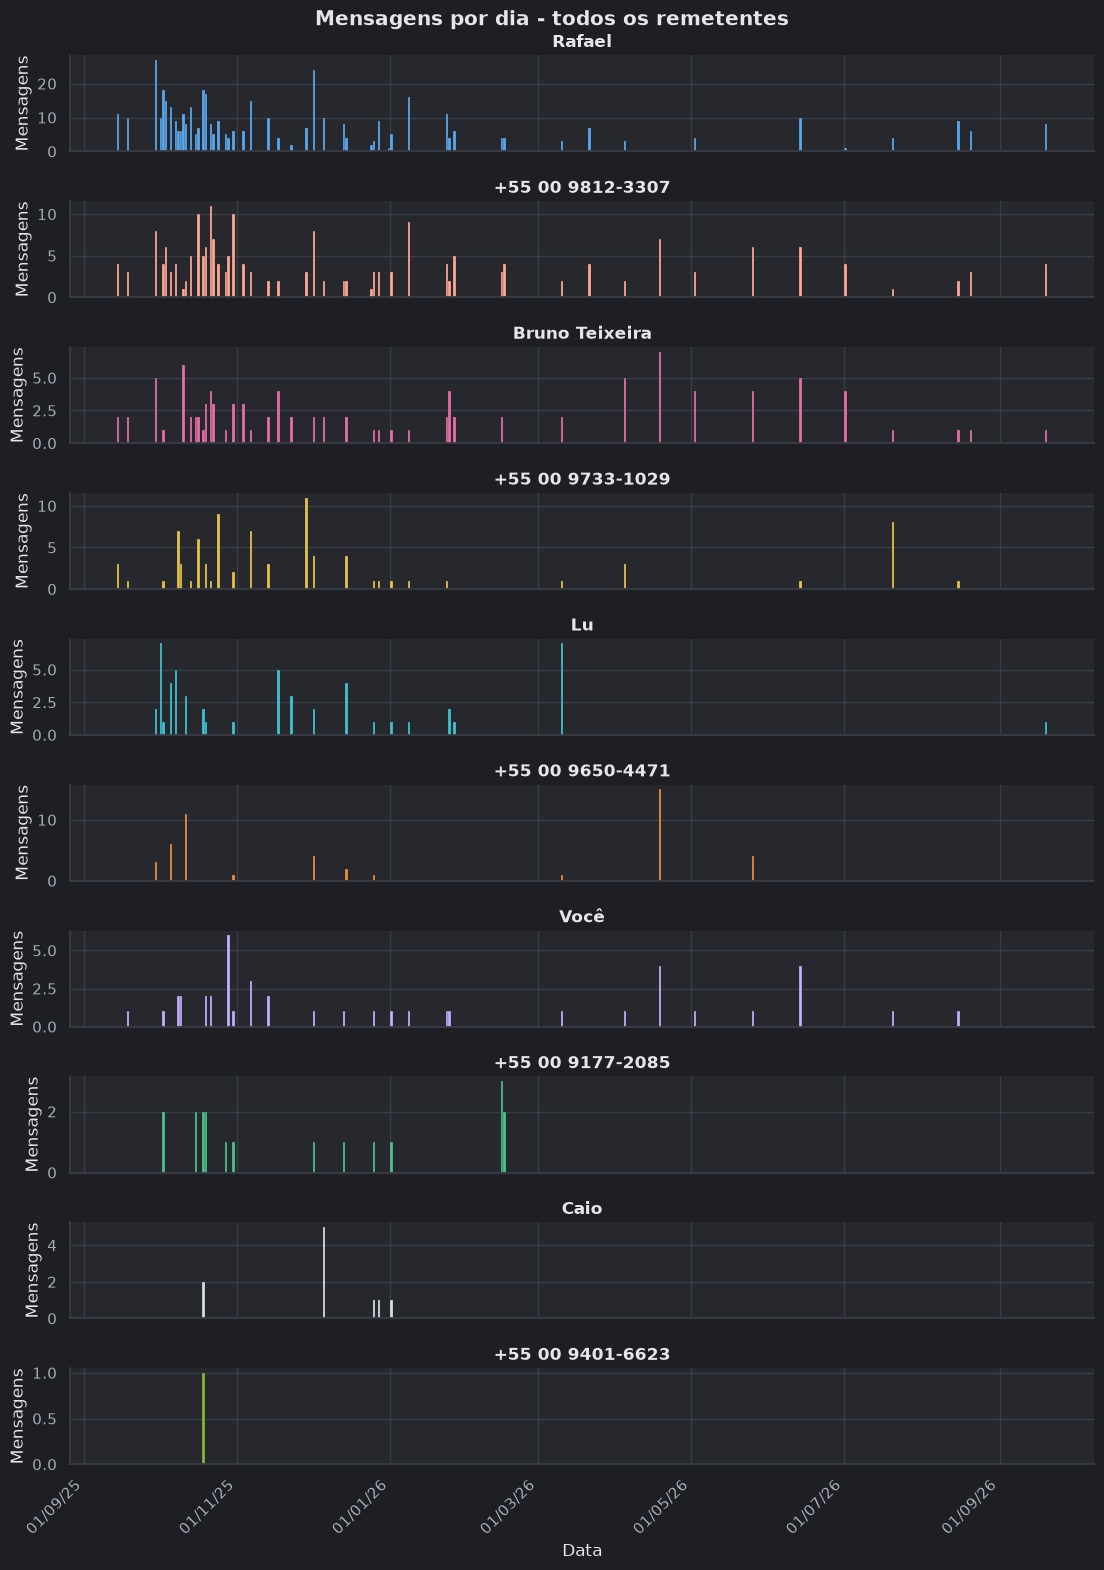

In [7]:
def mostrar_grafico_historico():
    if seletor_grafico.value == "Todos":
        fig = grafico_historico_remetente(df)
    else:
        fig = grafico_historico_remetente(df, seletor_grafico.value)
    saida_grafico_historico.update(fig)
    plt.close(fig)


seletor_grafico = widgets.Dropdown(options=["Todos"] + listar_remetentes(df), description="Remetente:")
seletor_grafico.observe(lambda mudanca: mostrar_grafico_historico(), names="value")
display(seletor_grafico)

fig = grafico_historico_remetente(df)
saida_grafico_historico = display(fig, display_id=True)
plt.close(fig)

---

## 7. Gráfico

Percentual de mensagens de cada remetente. Fatias menores que 3 % não mostram o número dentro da fatia:

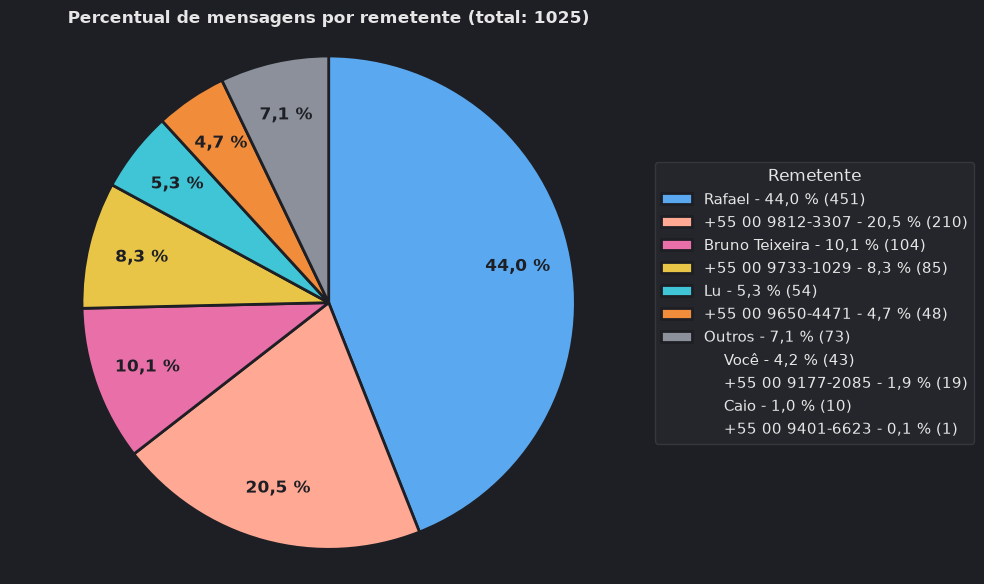

In [8]:
def mostrar_pizza():
    fig = grafico_pizza(df)
    saida_pizza.update(fig)
    plt.close(fig)


fig = grafico_pizza(df)
saida_pizza = display(fig, display_id=True)
plt.close(fig)

---

## 8. Gráfico de linhas

Mensagens ao longo do tempo, todos os remetentes no mesmo gráfico, uma cor por remetente. Escolha o agrupamento: por **dia** (padrão), por **semana** ou por **mês**, mais legível numa conversa longa.

Dropdown(description='Agrupar por:', options=(('Dia', 'D'), ('Semana', 'W'), ('Mês', 'MS')), value='D')

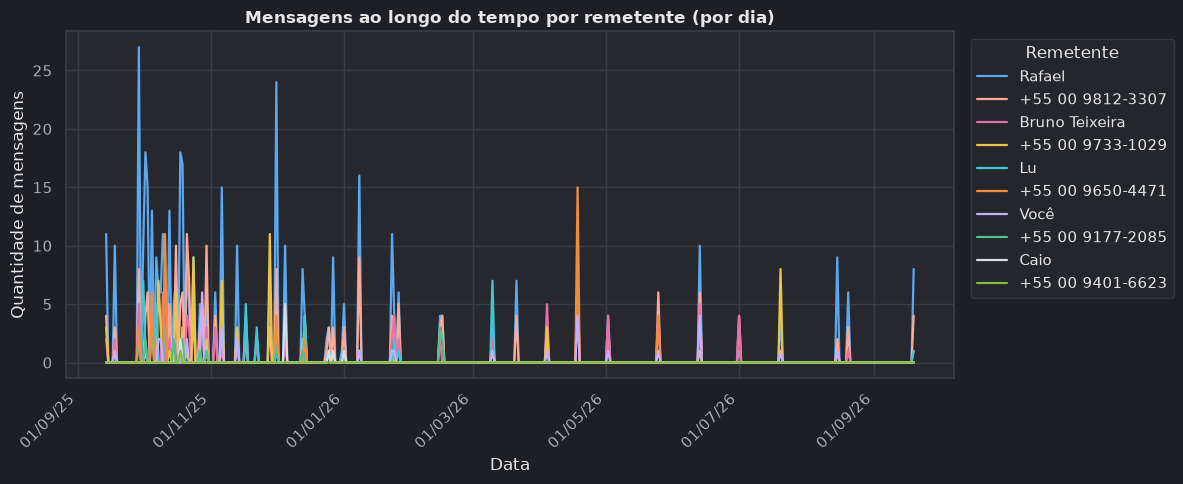

In [9]:
def mostrar_linhas():
    fig = grafico_linhas(df, freq=seletor_periodo.value)
    saida_linhas.update(fig)
    plt.close(fig)


seletor_periodo = widgets.Dropdown(
    options=[("Dia", "D"), ("Semana", "W"), ("Mês", "MS")],
    description="Agrupar por:",
)
seletor_periodo.observe(lambda mudanca: mostrar_linhas(), names="value")
display(seletor_periodo)

fig = grafico_linhas(df, freq=seletor_periodo.value)
saida_linhas = display(fig, display_id=True)
plt.close(fig)

---

# Conclusões

Consideramos algo como uma aplicação web para o desenvolvimento do projeto, mas consideramos que um notebook estaria mais próximo do assunto das aulas anteriores 
e portanto escolhemos utilizar o jupyter lab ao invés de algo como FastAPI